# 00 — Tải và kiểm tra dữ liệu
**Dự án:** Nhận diện khuôn mặt qua camera và chào hỏi theo tên

**Input:**
- LFW: `jessicali9530/lfw-dataset`
- CPLFW: `devvindan/crosspose-lfw-database-cplfw`

**Output:** Kaggle Dataset `<tài khoản>/face-data-index`
```
face-data-index/
├── lfw.csv           ← mỗi dòng 1 ảnh: person, path
└── cplfw_pairs.csv   ← mỗi dòng 1 cặp: path_1, path_2, same (1 = cùng người)
```

## Bước 1: Xem thư mục input

In [1]:
import os

for cur, dirs, files in os.walk('/kaggle/input'):
    depth = cur.count('/') - 2
    if depth > 6:
        continue
    n_img = sum(f.lower().endswith('.jpg') for f in files)
    others = [f for f in files if not f.lower().endswith('.jpg')]
    print('    ' * depth + os.path.basename(cur) + '/', f'[{n_img} ảnh]' if n_img else '', others[:5] if others else '')
    if len(dirs) > 5:
        print('    ' * (depth + 1) + f'... {len(dirs)} thư mục con')
        dirs[:] = []

input/  
    datasets/  
        jessicali9530/  
            lfw-dataset/  ['lfw_allnames.csv', 'lfw_readme.csv', 'matchpairsDevTest.csv', 'matchpairsDevTrain.csv', 'mismatchpairsDevTest.csv']
                lfw-deepfunneled/  
                    lfw-deepfunneled/  
                        ... 5749 thư mục con
        devvindan/  
            crosspose-lfw-database-cplfw/  ['pairs_CPLFW.txt']
                CP_landmarks/  
                    CP_landmarks/  ['AJ_Cook_1_5loc_attri.txt', 'AJ_Cook_2_5loc_attri.txt', 'AJ_Cook_3_5loc_attri.txt', 'AJ_Lamas_1_5loc_attri.txt', 'AJ_Lamas_2_5loc_attri.txt']
                aligned images/  
                    aligned images/ [11652 ảnh] 
                cp_landmarks/  
                    CP_landmarks/  ['AJ_Cook_1_5loc_attri.txt', 'AJ_Cook_2_5loc_attri.txt', 'AJ_Cook_3_5loc_attri.txt', 'AJ_Lamas_1_5loc_attri.txt', 'AJ_Lamas_2_5loc_attri.txt']
                images/  
                    images/ [11652 ảnh] 


## Bước 2: Điền đường dẫn
Nhìn cây thư mục ở Bước 1 rồi sửa 3 dòng dưới cho đúng.

In [2]:
LFW_DIR     = '/kaggle/input/datasets/jessicali9530/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled'   # chứa các folder theo tên người
CPLFW_DIR   = '/kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/images'           # ảnh gốc (chưa cắt), giống kiểu ảnh LFW
CPLFW_PAIRS = '/kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/pairs_CPLFW.txt'  # file danh sách cặp

for p in [LFW_DIR, CPLFW_DIR, CPLFW_PAIRS]:
    print('OK   ' if os.path.exists(p) else 'SAI  ', p)

OK    /kaggle/input/datasets/jessicali9530/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled
OK    /kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/images
OK    /kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/pairs_CPLFW.txt


## Bước 3: LFW

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

rows = []
for person in sorted(os.listdir(LFW_DIR)):
    for f in sorted(os.listdir(os.path.join(LFW_DIR, person))):
        rows.append({'person': person, 'path': os.path.join(LFW_DIR, person, f)})
lfw = pd.DataFrame(rows)

counts = lfw.person.value_counts()
print(f'Số ảnh  : {len(lfw):,}  (kỳ vọng 13.233)')
print(f'Số người: {len(counts):,}  (kỳ vọng 5.749)')
print(f'Người có >= 10 ảnh: {(counts >= 10).sum()}')

Số ảnh  : 13,233  (kỳ vọng 13.233)
Số người: 5,749  (kỳ vọng 5.749)
Người có >= 10 ảnh: 158


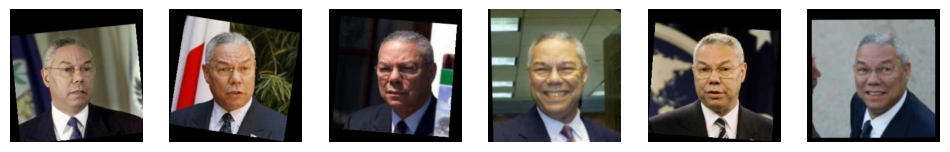

In [4]:
# Xem 6 ảnh của cùng một người
sub = lfw[lfw.person == 'Colin_Powell'].head(6)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, p in zip(axes, sub.path):
    ax.imshow(Image.open(p)); ax.axis('off')
plt.show()

## Bước 4: CPLFW
Xem vài dòng đầu của file cặp ảnh trước, để biết định dạng.

In [5]:
with open(CPLFW_PAIRS) as f:
    lines = [l.split() for l in f if l.strip()]
print(f'Số dòng: {len(lines)}')
for l in lines[:6]:
    print(l)

Số dòng: 6000
['Ingrid_Betancourt_1.jpg', 'Ingrid_Betancourt_2.jpg', '1']
['Jonathan_Woodgate_1.jpg', 'Jonathan_Woodgate_3.jpg', '1']
['Anders_Fogh_Rasmussen_1.jpg', 'Anders_Fogh_Rasmussen_2.jpg', '1']
['Elinor_Caplan_1.jpg', 'Elinor_Caplan_2.jpg', '1']
['Brad_Johnson_1.jpg', 'Brad_Johnson_2.jpg', '1']
['Candice_Bergen_2.jpg', 'Candice_Bergen_3.jpg', '1']


In [6]:
# Tìm ảnh theo tên trong CPLFW_DIR, kể cả thư mục con
found = {}
for cur, _, files in os.walk(CPLFW_DIR):
    for f in files:
        found.setdefault(f, os.path.join(cur, f))
print(f'Tìm thấy {len(found):,} ảnh. Ví dụ:')
for f in list(found.values())[:3]:
    print('  ', f)

# Mỗi dòng: anh_1 anh_2 nhan  (nhan 1 = cùng người, 0 = khác người)
pairs = pd.DataFrame({
    'path_1': [found.get(l[0]) for l in lines],
    'path_2': [found.get(l[1]) for l in lines],
    'same'  : [int(l[2]) for l in lines],
})
pairs['ok'] = pairs.path_1.notna() & pairs.path_2.notna()
print()

print(f'Số cặp     : {len(pairs):,}  (kỳ vọng 6.000)')
print(f'Cùng người : {pairs.same.sum():,}')
print(f'Thiếu ảnh  : {(~pairs.ok).sum()}')

Tìm thấy 11,652 ảnh. Ví dụ:
   /kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/images/images/AJ_Cook_1.jpg
   /kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/images/images/AJ_Cook_2.jpg
   /kaggle/input/datasets/devvindan/crosspose-lfw-database-cplfw/images/images/AJ_Cook_3.jpg

Số cặp     : 6,000  (kỳ vọng 6.000)
Cùng người : 3,000
Thiếu ảnh  : 0


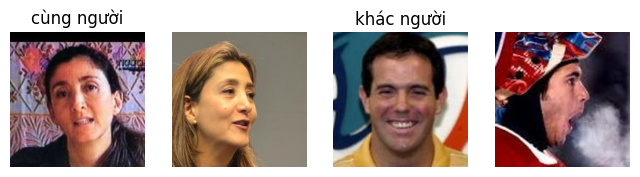

In [7]:
# Xem 1 cặp cùng người và 1 cặp khác người
good = pairs[pairs.ok]
show = pd.concat([good[good.same == 1].head(1), good[good.same == 0].head(1)])
fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for i, (_, r) in enumerate(show.iterrows()):
    for j, p in enumerate([r.path_1, r.path_2]):
        axes[2 * i + j].imshow(Image.open(p)); axes[2 * i + j].axis('off')
    axes[2 * i].set_title('cùng người' if r.same else 'khác người')
plt.show()

## Bước 5: Lưu

In [8]:
OUTPUT_DIR = '/kaggle/working/face-data-index'
os.makedirs(OUTPUT_DIR, exist_ok=True)

lfw.to_csv(f'{OUTPUT_DIR}/lfw.csv', index=False)
pairs[pairs.ok].drop(columns='ok').to_csv(f'{OUTPUT_DIR}/cplfw_pairs.csv', index=False)
print('Đã lưu lfw.csv và cplfw_pairs.csv')

Đã lưu lfw.csv và cplfw_pairs.csv


## Bước 6: Tạo Kaggle Dataset

In [9]:
# Tự động lưu kết quả thành Kaggle Dataset (Private)
import json, subprocess

dataset_name = os.path.basename(OUTPUT_DIR)
kaggle_user  = [l.split(':')[1].strip() for l in
                subprocess.run('kaggle config view', shell=True,
                               capture_output=True, text=True)
                .stdout.split('\n') if 'username' in l][0]

with open(f'{OUTPUT_DIR}/dataset-metadata.json', 'w') as f:
    json.dump({
        'title'   : dataset_name,
        'id'      : f'{kaggle_user}/{dataset_name}',
        'licenses': [{'name': 'CC0-1.0'}]
    }, f)

check = subprocess.run(f'kaggle datasets list --user {kaggle_user} --search {dataset_name}',
                       shell=True, capture_output=True, text=True)
if dataset_name in check.stdout:
    os.system(f'kaggle datasets version -p {OUTPUT_DIR} -m "update"')
else:
    os.system(f'kaggle datasets create -p {OUTPUT_DIR}')

print(f'Done! {kaggle_user}/{dataset_name}')

Starting upload for file cplfw_pairs.csv


100%|██████████| 1.12M/1.12M [00:00<00:00, 1.86MB/s]
  0%|          | 0.00/1.71M [00:00<?, ?B/s]

Upload successful: cplfw_pairs.csv (1MB)
Starting upload for file lfw.csv


100%|██████████| 1.71M/1.71M [00:00<00:00, 2.75MB/s]


Upload successful: lfw.csv (2MB)
Request failed: 429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/datasets.DatasetApiService/CreateDataset. Will retry in 0.8 seconds
Request failed: 429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/datasets.DatasetApiService/CreateDataset. Will retry in 1.4 seconds
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/minhbodoi/face-data-index
Done! minhbodoi/face-data-index
